MD analysis pipeline
Nov 10, 2026
Remove solvent and salt, slice trajectories to thin out, compute RMSF

In [1]:
import MDAnalysis as mda
import mdtraj as md
import os
import matplotlib.pyplot as plt
import numpy as np

1. Remove solvent and thin out trajectories

In [7]:
# load topology and trajectory 
top  = "/n/home00/ewang03/scratch/GroEL/runs/2026-11-07_58169745/m20i_nadph_tmp_start.pdb"
traj = "/n/home00/ewang03/scratch/GroEL/runs/2026-11-07_58169745/m20i_with_ligands.xtc"

u = mda.Universe(top, traj)   # topology first, then trajectory

print(u)                      # <Universe with 27716 atoms>
print(len(u.trajectory))      # number of frames
print(u.trajectory.dt)        # time between frames (ps)

protein = u.select_atoms("protein or resname TMP NDP")   # protein + TMP + NADPH; drops water (HOH) and ions (NA, CL)
protein.write("/n/home00/ewang03/scratch/GroEL/runs/2026-11-07_58169745/m20i_nadph_tmp_dry.pdb")  # write dry pdb file

# create new thinned out trajectory file
with mda.Writer("/n/home00/ewang03/scratch/GroEL/runs/2026-11-07_58169745/m20i_with_ligands_sparse.xtc", protein.n_atoms) as W:
    for ts in u.trajectory[::100]: # save every 100th trajectory (time between frames is 1 ns)
        W.write(protein)

<Universe with 24494 atoms>
100000
10.0


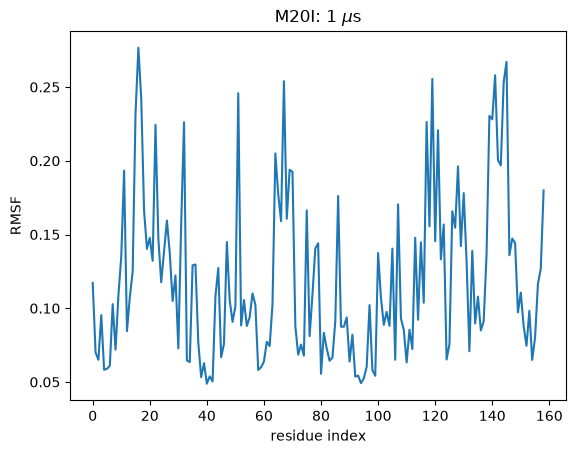

In [11]:
pdb = "/n/home00/ewang03/scratch/GroEL/runs/2026-11-07_58169745/m20i_nadph_tmp_dry.pdb"
xtc = "/n/home00/ewang03/scratch/GroEL/runs/2026-11-07_58169745/m20i_with_ligands_sparse.xtc"

top = md.load_topology(pdb)
traj = md.load(xtc, top=top, atom_indices=top.select("protein")) # only include protein atoms

# Align every frame on the C-alpha atoms, then RMSF of each C-alpha about its average position
ca = traj.topology.select("name CA")
traj.superpose(traj, 0, atom_indices=ca)
rmsf = md.rmsf(traj, None, mode='residue')

# plot RMSF vs. residue index
res_ind = np.arange(traj.n_residues)
plt.plot(res_ind, rmsf)
plt.title(r'M20I: 1 $\mu$s')
plt.xlabel('residue index')
plt.ylabel('RMSF')
plt.show()

2. Run the pipeline on the 1 µs replicas

Jobs after 58169745, except 58170032 and 58170052. 58169745 itself (M20I replica 01, processed above) is included so the comparison has every finished replica.
Runs that haven't finished yet are skipped; rerun these cells once they finish. Thinning is skipped for runs that already have a `_sparse.xtc`, so reruns only process new runs.

In [13]:
import warnings
from glob import glob

warnings.filterwarnings("ignore", message="Found no information for attr")  # PDB charge column, harmless

RUNS = "/n/home00/ewang03/scratch/GroEL/runs"
JOBS = [58169745,                                        # M20I replica 01 (thinned above)
        58169764, 58169814, 58169867, 58169960, 58169975, 58170061, 58170068]
STRIDE = 100   # keep every 100th frame: frames are saved every 10 ps, so one frame per 1 ns


def read_run_info(run_dir):
    with open(os.path.join(run_dir, "run_info.txt")) as f:
        return {k.strip(): v.strip() for k, v in (line.split(":", 1) for line in f if ":" in line)}


def thin_run(run_dir, prefix):
    '''Step 1: write a dry topology and a thinned, dry trajectory. Skipped if the thinned trajectory already exists'''
    dry_pdb = os.path.join(run_dir, f"{prefix}_nadph_tmp_dry.pdb")
    sparse_xtc = os.path.join(run_dir, f"{prefix}_with_ligands_sparse.xtc")
    if not os.path.exists(sparse_xtc):
        u = mda.Universe(os.path.join(run_dir, f"{prefix}_nadph_tmp_start.pdb"),
                         os.path.join(run_dir, f"{prefix}_with_ligands.xtc"))
        solute = u.select_atoms("protein or resname TMP NDP")   # protein + TMP + NADPH; drops water and ions
        solute.write(dry_pdb)
        tmp = sparse_xtc[:-4] + ".part.xtc"    # renamed when complete, so an interrupted run is redone next time
        with mda.Writer(tmp, solute.n_atoms) as W:
            for ts in u.trajectory[::STRIDE]:
                W.write(solute)
        os.replace(tmp, sparse_xtc)
    return dry_pdb, sparse_xtc


runs = {}   # job name (e.g. wt_with_ligands_1us_01) -> (dry pdb, thinned xtc)
for job in JOBS:
    run_dir = glob(f"{RUNS}/*_{job}")[0]   # the job's original folder (not a _requeue folder)
    info = read_run_info(run_dir)
    name = info["job_name"]
    if "finished" not in info:
        print(f"{job} {name}: not finished yet, skipped")
        continue
    runs[name] = thin_run(run_dir, name.split("_with_ligands")[0])   # prefix 'wt' or 'm20i'
    print(f"{job} {name}: thinned")

58169745 m20i_with_ligands_1us_01: thinned
58169764 wt_with_ligands_1us_01: thinned
58169814 wt_with_ligands_1us_02: thinned
58169867 m20i_with_ligands_1us_02: thinned
58169960 m20i_with_ligands_1us_03: thinned
58169975 wt_with_ligands_1us_03: thinned
58170061 m20i_with_ligands_1us_05: not finished yet, skipped
58170068 wt_with_ligands_1us_05: not finished yet, skipped


In [14]:
# Step 2: RMSF of every thinned run, same method as above: align each frame on the C-alpha atoms, then
# per-residue RMSF = mass-weighted mean over the residue's atoms (side chains and H included)
rmsf_1us = {}   # job name -> (residue numbers, RMSF in Angstrom)
for name, (pdb, xtc) in runs.items():
    top = md.load_topology(pdb)
    traj = md.load(xtc, top=top, atom_indices=top.select("protein"))   # protein atoms only
    ca = traj.topology.select("name CA")
    traj.superpose(traj, 0, atom_indices=ca)
    resseq = np.array([res.resSeq for res in traj.topology.residues])
    rmsf_1us[name] = (resseq, md.rmsf(traj, None, mode="residue") * 10)   # nm -> Angstrom
    print(f"{name}: {traj.n_frames} frames ({traj.time[-1] / 1000:.0f} ns), {traj.n_residues} residues")

# Group replicas by system ('wt' / 'm20i' from the job name)
by_system = {}
for name, (resseq, r) in rmsf_1us.items():
    by_system.setdefault(name.split("_with_ligands")[0], []).append(r)
for system, reps in by_system.items():
    print(f"{system}: {len(reps)} replicas")

m20i_with_ligands_1us_01: 1000 frames (999 ns), 159 residues
wt_with_ligands_1us_01: 1000 frames (999 ns), 159 residues
wt_with_ligands_1us_02: 1000 frames (999 ns), 159 residues
m20i_with_ligands_1us_02: 1000 frames (999 ns), 159 residues
m20i_with_ligands_1us_03: 1000 frames (999 ns), 159 residues
wt_with_ligands_1us_03: 1000 frames (999 ns), 159 residues
m20i: 3 replicas
wt: 3 replicas


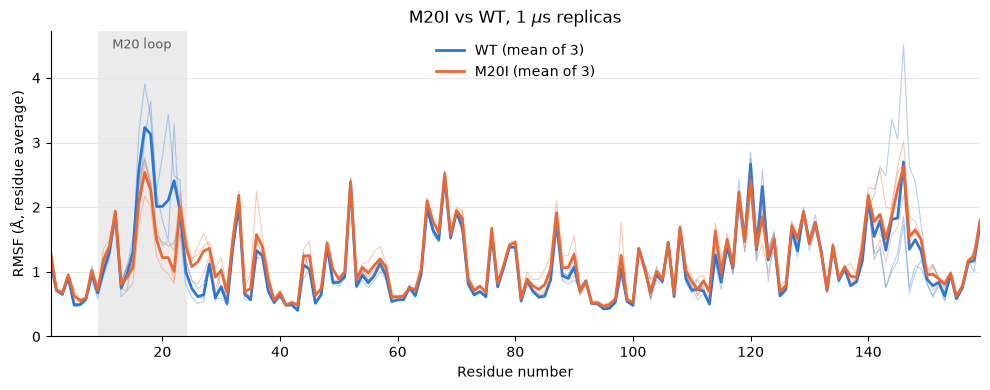

In [15]:
fig, ax = plt.subplots(figsize=(10, 4))

# Shade the Met20 loop (residues 9-24), where the M20I mutation sits
ax.axvspan(9, 24, color="0.92", zorder=0)
ax.text(16.5, 0.98, "M20 loop", transform=ax.get_xaxis_transform(), ha="center", va="top", fontsize=9, color="0.35")

resseq = next(iter(rmsf_1us.values()))[0]   # same 159 residues in every run
for (system, label), color in zip([("wt", "WT"), ("m20i", "M20I")], ["#2a78d6", "#eb6834"]):
    reps = np.array(by_system.get(system, []))
    if len(reps) == 0:
        continue
    for r in reps:   # individual replicas, thin and faint
        ax.plot(resseq, r, color=color, lw=0.8, alpha=0.35)
    ax.plot(resseq, reps.mean(axis=0), color=color, lw=2, label=f"{label} (mean of {len(reps)})")

ax.set_title(r"M20I vs WT, 1 $\mu$s replicas")
ax.set_xlabel("Residue number")
ax.set_ylabel("RMSF (Å, residue average)")
ax.set_xlim(1, 159)
ax.set_ylim(bottom=0)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="0.9", lw=0.8)
ax.set_axisbelow(True)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

In [5]:
RUNS = "/n/home00/ewang03/scratch/GroEL/runs"
systems = {  # name: (trajectory, full solvated topology -- must have the same atoms as the trajectory)
    "WT":   (f"{RUNS}/2026-11-04_57868420/wt_with_ligands.xtc",   f"{RUNS}/2026-11-04_57868420/wt_nadph_tmp_start.pdb"),
    "M20I": (f"{RUNS}/2026-11-04_57886515/m20i_with_ligands.xtc", f"{RUNS}/2026-11-04_57886515/m20i_nadph_tmp_start.pdb"),
}

rmsf = {}
for name, (xtc, pdb) in systems.items():
    # Load only the protein atoms (drops TMP, NADPH, water and ions; ~20 s per run)
    top = md.load_topology(pdb)
    traj = md.load(xtc, top=top, atom_indices=top.select("protein"))

    # Align every frame on the C-alpha atoms, then RMSF of each C-alpha about its average position
    ca = traj.topology.select("name CA")
    traj.superpose(traj, 0, atom_indices=ca)
    resseq = np.array([traj.topology.atom(i).residue.resSeq for i in ca])
    rmsf[name] = (resseq, md.rmsf(traj, None, atom_indices=ca) * 10)  # nm -> Angstrom

    print(f"{name}: {traj.n_frames} frames, {len(ca)} residues")

WT: 10000 frames, 159 residues
M20I: 10000 frames, 159 residues


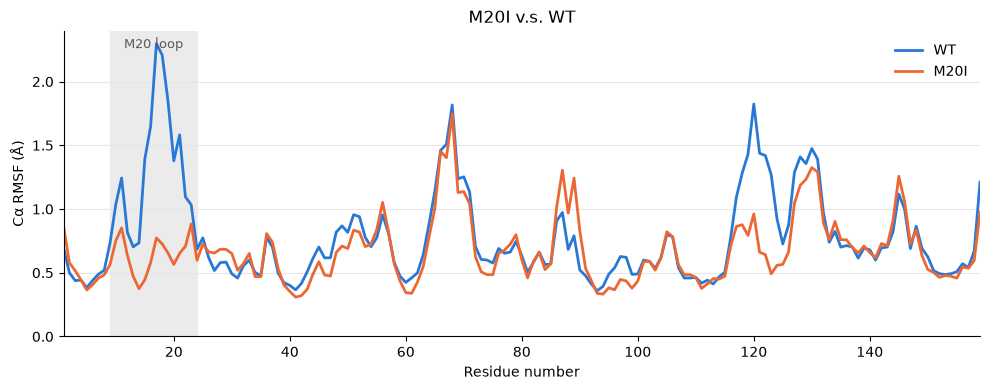

In [8]:
fig, ax = plt.subplots(figsize=(10, 4))

# Shade the Met20 loop (residues 9-24), where the M20I mutation sits
ax.axvspan(9, 24, color="0.92", zorder=0)
ax.text(16.5, 0.98, "M20 loop", transform=ax.get_xaxis_transform(), ha="center", va="top", fontsize=9, color="0.35")

for (name, (resseq, r)), color in zip(rmsf.items(), ["#2a78d6", "#eb6834"]):
    ax.plot(resseq, r, color=color, lw=2, label=name)

ax.set_title("M20I v.s. WT")
ax.set_xlabel("Residue number")
ax.set_ylabel("Cα RMSF (Å)")
ax.set_xlim(1, 159)
ax.set_ylim(bottom=0)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="0.9", lw=0.8)
ax.set_axisbelow(True)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()